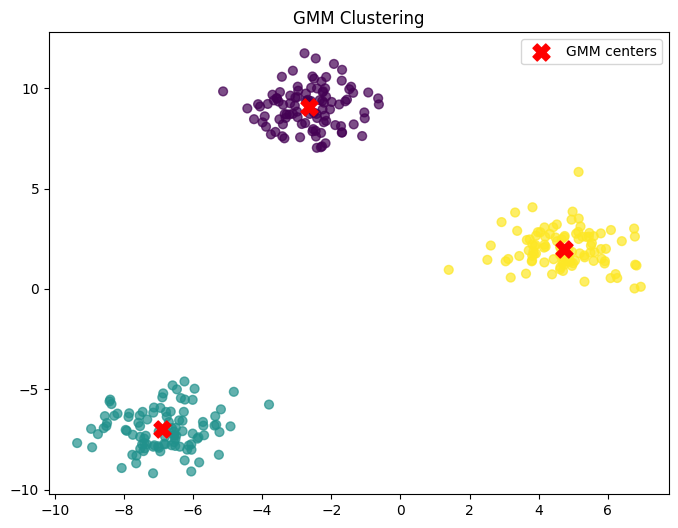

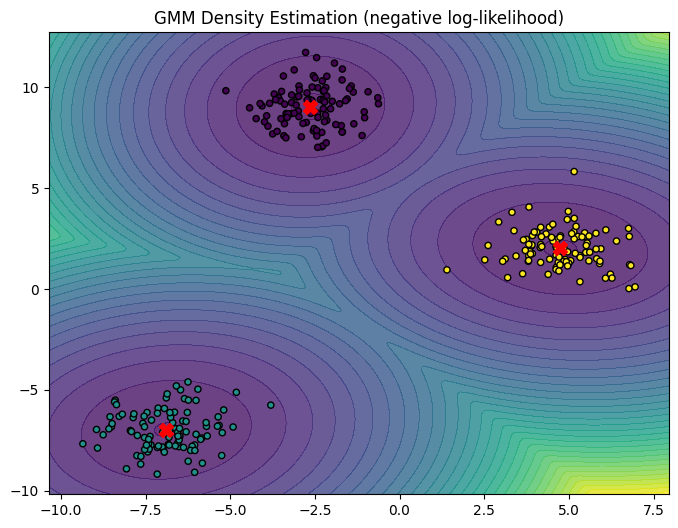

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

np.random.seed(42)

# Generate synthetic data (same idea as PDF)
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Fit GMM
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42)
gmm.fit(X)

# Predict cluster labels
labels = gmm.predict(X)

# Scatter with cluster coloring and cluster centers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=40, alpha=0.7)
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1], c='red', s=150, marker='X', label='GMM centers')
plt.title("GMM Clustering")
plt.legend()
plt.show()

# Density / negative log-likelihood contour (as in PDF)
# Create grid covering data
x = np.linspace(X[:, 0].min() - 1.0, X[:, 0].max() + 1.0, 200)
y_grid = np.linspace(X[:, 1].min() - 1.0, X[:, 1].max() + 1.0, 200)
X_grid, Y_grid = np.meshgrid(x, y_grid)
grid_points = np.column_stack([X_grid.ravel(), Y_grid.ravel()])

# score_samples returns log density; we take negative so lower is higher likelihood valley visualization
Z = -gmm.score_samples(grid_points)
Z = Z.reshape(X_grid.shape)

plt.figure(figsize=(8, 6))
plt.contourf(X_grid, Y_grid, Z, levels=30, cmap='viridis', alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=20, edgecolor='k')
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1], c='red', s=100, marker='X')
plt.title("GMM Density Estimation (negative log-likelihood)")
plt.show()